<a href="https://colab.research.google.com/github/manuelabr241-eng/Simuladordecalcularuncredito/blob/main/S21_Taller5_Series_Temporales_Python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Taller 5 · Series temporales financieras con Python
**Lenguajes de Programación · Ingeniería Financiera · ITM · Sesión 21**

**Pregunta que orienta el taller:** a partir de la serie de precios de una acción durante un año, ¿cuánto rindió, cuánto riesgo asumió, cuánto llegó a perder y qué se gana al combinarla con otra?

El notebook desarrolla los mismos ocho conceptos de la página de la sesión, con datos reales de Yahoo Finance:

1. Serie temporal
2. Rendimiento
3. Tendencia y promedio móvil
4. Volatilidad
5. Rendimiento acumulado
6. Máxima caída
7. Correlación y diversificación
8. Análisis completo

Cada sección presenta la definición y su fórmula, el código que la implementa explicado línea por línea, una celda para completar (los espacios `___`) y una pregunta de análisis. Las respuestas de las celdas están en **Ver respuesta**. Al final se encuentra el **reto del Taller 5**.

## 0 · Preparación del entorno
Las celdas de código se ejecutan con **Shift + Enter** y deben ejecutarse en orden, porque cada una utiliza los resultados de las anteriores.

Una **librería** es un conjunto de funciones ya programadas. En Colab solo es necesario instalar `yfinance`; las demás vienen incluidas. La instrucción `import ... as ...` carga la librería y le asigna un nombre corto.

In [ ]:
!pip install -q yfinance

import yfinance as yf               # descarga de precios desde Yahoo Finance
import pandas as pd                 # tablas indexadas por fecha
import numpy as np                  # operaciones numéricas
import matplotlib.pyplot as plt     # gráficas

plt.rcParams["figure.figsize"] = (11, 4)

---
## 1 · Serie temporal
Una **serie temporal** es un conjunto de observaciones de una variable registradas en momentos sucesivos y separados por intervalos regulares:

$$\{P_1, P_2, \dots, P_T\}$$

donde $P_t$ es el precio de cierre en el periodo $t$. Toda serie temporal tiene un **índice** (la fecha de cada observación) y una **frecuencia** (el intervalo entre observaciones).

### 1.1 Descarga de los datos
Se descargan tres series para 2025: Apple (`AAPL`), el ETF `SPY`, que representa al mercado, y Coca-Cola (`KO`).

In [ ]:
tickers = ["AAPL", "SPY", "KO"]               # lista con los símbolos

datos = yf.download(tickers,
                    start="2025-01-01",       # fecha inicial
                    end="2026-01-01",         # fecha final (no incluida)
                    auto_adjust=True,         # precios ajustados por dividendos y divisiones
                    progress=False)

precios = datos["Close"]                      # precio de cierre de las tres acciones
precios.head()                                # primeras cinco filas

Ticker,AAPL,KO,SPY
Date,,,
2025-01-02,242.093140,58.923294,573.375671
2025-01-03,241.606674,58.837543,580.544861
2025-01-06,243.234848,57.941879,583.889221
2025-01-07,240.464966,57.970463,577.288879
2025-01-08,240.951385,58.799427,578.132324


`precios` es un **DataFrame**: una tabla con una columna por acción. La primera columna, a la izquierda, contiene las fechas y constituye el **índice** de la tabla. Al seleccionar una sola columna se obtiene una **Series**, que es la serie temporal de una acción.

In [ ]:
precio = precios["AAPL"]       # serie temporal del precio de Apple
precio.head()

,AAPL
Date,
2025-01-02,242.093140
2025-01-03,241.606674
2025-01-06,243.234848
2025-01-07,240.464966
2025-01-08,240.951385


### Componentes, tipos de análisis y preprocesamiento
Una serie temporal financiera se compone de **tendencia** $T_t$ (dirección de largo plazo), **estacionalidad o ciclo** $S_t$ (patrones ligados al calendario) y **componente irregular** $\varepsilon_t$ (fluctuaciones impredecibles).

El análisis es **univariado** cuando estudia una sola variable (el precio de Apple) y **multivariado** cuando estudia la relación entre varias (Apple, Coca-Cola y SPY).

Antes de calcular cualquier medida se realiza el **preprocesamiento**:
1. **Indexación temporal:** el índice debe ser de tipo fecha y estar ordenado.
2. **Valores ausentes:** los festivos o suspensiones generan `NaN`; se eliminan con `dropna()` / `na.omit()`.
3. **Alineación de calendarios:** con varios activos se conservan solo las fechas comunes.

### 1.2 Índice y número de observaciones
Complete la celda para obtener la primera fecha, la última fecha y el número de observaciones.

In [33]:
print("Primera fecha:", precio.index.min())
print("Última fecha: ", precio.index.max())
print("Observaciones:", len(precio))

Primera fecha: 2025-01-02 00:00:00
Última fecha:  2025-12-31 00:00:00
Observaciones: 250


> ✍️ **Pregunta de análisis.** El año tiene 365 días. ¿Por qué la serie contiene un número menor de observaciones?
>
> *Respuesta:* La serie contiene un número menor de observaciones porque los mercados bursátiles (como las bolsas de valores donde cotizan estas acciones) únicamente operan en días hábiles o días de negociación.

<details><summary><b>Ver respuesta</b></summary>

```python
print("Primera fecha:", precio.index.min())
print("Última fecha: ", precio.index.max())
print("Observaciones:", len(precio))
```
</details>

### 1.3 Gráfica de la serie

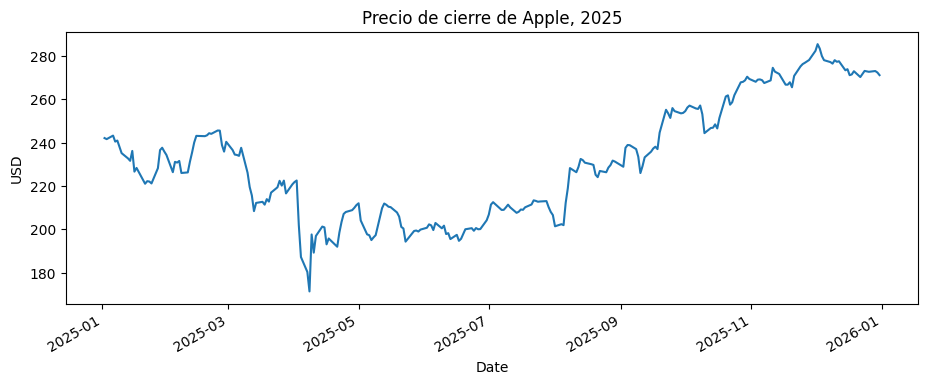

In [34]:
precio.plot(title="Precio de cierre de Apple, 2025")
plt.ylabel("USD")
plt.show()

### 1.4 Cambio de frecuencia
El método `resample` agrupa las observaciones en periodos más largos: `"W"` para semanas y `"ME"` para meses. El método `.last()` conserva el último precio de cada periodo.

Observaciones diarias: 250 | semanales: 53 | mensuales: 12


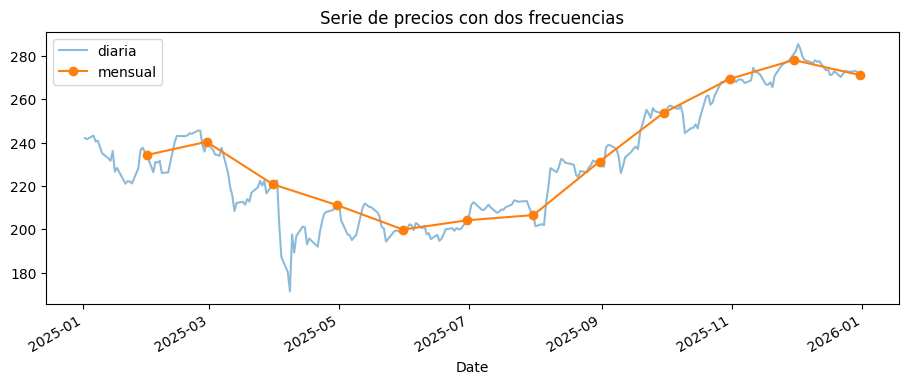

In [35]:
semanal = precio.resample("W").last()
mensual = precio.resample("ME").last()

print("Observaciones diarias:", len(precio), "| semanales:", len(semanal), "| mensuales:", len(mensual))
precio.plot(label="diaria", alpha=0.5)
mensual.plot(label="mensual", marker="o")
plt.legend(); plt.title("Serie de precios con dos frecuencias"); plt.show()

> ✍️ **Pregunta de análisis.** ¿Qué información conserva la serie mensual y qué información se pierde respecto a la serie diaria?
>
> *Respuesta:* La frecuencia y dispersión exacta de las operaciones cotidianas, ya que las variaciones diarias se suavizan y se agrupan en un solo valor por mes.

La volatilidad diaria y las fluctuaciones que ocurren de un día para otro.

<details><summary><b>Ver respuesta</b></summary>

```python
mensual = precio.resample("ME").last()
```
</details>

---
## 2 · Rendimiento
El **rendimiento simple** es la variación porcentual del precio entre dos periodos consecutivos:

$$r_t = \frac{P_t}{P_{t-1}} - 1$$

El rendimiento permite comparar acciones con precios distintos y oscila alrededor de un valor cercano a cero, mientras que el precio cambia de nivel con el tiempo. Por esa razón el análisis se realiza sobre los rendimientos.

### 2.1 Cálculo para un día
`iloc[k]` selecciona la observación en la posición `k`. En Python las posiciones comienzan en 0.

In [36]:
P_anterior = precio.iloc[0]          # primer día
P_actual = precio.iloc[1]            # segundo día

r = P_actual / P_anterior - 1
print("P(t-1) =", round(P_anterior, 2), "| P(t) =", round(P_actual, 2))
print("r(t) =", round(r * 100, 2), "%")

P(t-1) = 242.09 | P(t) = 241.61
r(t) = -0.2 %


### 2.2 Cálculo para toda la serie
El método `shift(1)` desplaza la serie una posición, de modo que en cada fecha queda el precio del periodo anterior. La tabla muestra $P_t$ y $P_{t-1}$ alineados:

In [37]:
tabla = pd.DataFrame({"P_t": precio, "P_t-1": precio.shift(1)})
tabla.head()

,P_t,P_t-1
Date,,
2025-01-02,242.093140,NaN
2025-01-03,241.606674,242.093140
2025-01-06,243.234848,241.606674
2025-01-07,240.464966,243.234848
2025-01-08,240.951385,240.464966


Complete la fórmula del rendimiento con las columnas de la tabla:

In [38]:
tabla["r_t"] = tabla["P_t"] / tabla["P_t-1"] - 1
tabla.head()

,P_t,P_t-1,r_t
Date,,,
2025-01-02,242.093140,NaN,NaN
2025-01-03,241.606674,242.093140,-0.002009
2025-01-06,243.234848,241.606674,0.006739
2025-01-07,240.464966,243.234848,-0.011388
2025-01-08,240.951385,240.464966,0.002023


<details><summary><b>Ver respuesta</b></summary>

```python
tabla["r_t"] = tabla["P_t"] / tabla["P_t-1"] - 1
```
</details>

pandas implementa este cálculo con el método `pct_change()`. La primera observación queda vacía (`NaN`) porque no existe un precio anterior; `dropna()` la elimina.

In [40]:
rend = precio.pct_change().dropna()
rend.head()

,AAPL
Date,
2025-01-03,-0.002009
2025-01-06,0.006739
2025-01-07,-0.011388
2025-01-08,0.002023
2025-01-10,-0.024104


<details><summary><b>Ver respuesta</b></summary>

```python
rend = precio.pct_change().dropna()
```
</details>

### Estacionariedad, rezagos y autocorrelación
Una serie es **estacionaria en sentido débil** cuando su media y su varianza no cambian en el tiempo. Los precios no lo son: cambian de nivel. Los rendimientos sí lo son de forma aproximada: oscilan alrededor de cero con dispersión acotada. Por eso las volatilidades y correlaciones se calculan sobre rendimientos.

$P_{t-1}$ es el **primer rezago** de la serie. La **autocorrelación** mide la correlación de la serie con sus propios rezagos. En los rendimientos diarios suele ser cercana a cero, pero la volatilidad persiste: los días agitados tienden a agruparse, y por eso se mide en ventanas móviles (sección 4).

### 2.3 Serie de precios y serie de rendimientos

> ✍️ **Pregunta de análisis.** ¿Alrededor de qué valor oscilan los rendimientos? ¿Los días con variaciones grandes se distribuyen de manera uniforme durante el año o se concentran en algunos periodos?
>
> *Respuesta:* Los rendimientos oscilan alrededor de un valor cercano a cero.

Por su parte, los días con variaciones grandes no se distribuyen de manera uniforme a lo largo del año, sino que tienden a concentrarse en determinados periodos (reflejando la persistencia de la volatilidad, donde los días agitados o con movimientos drásticos suelen agruparse).

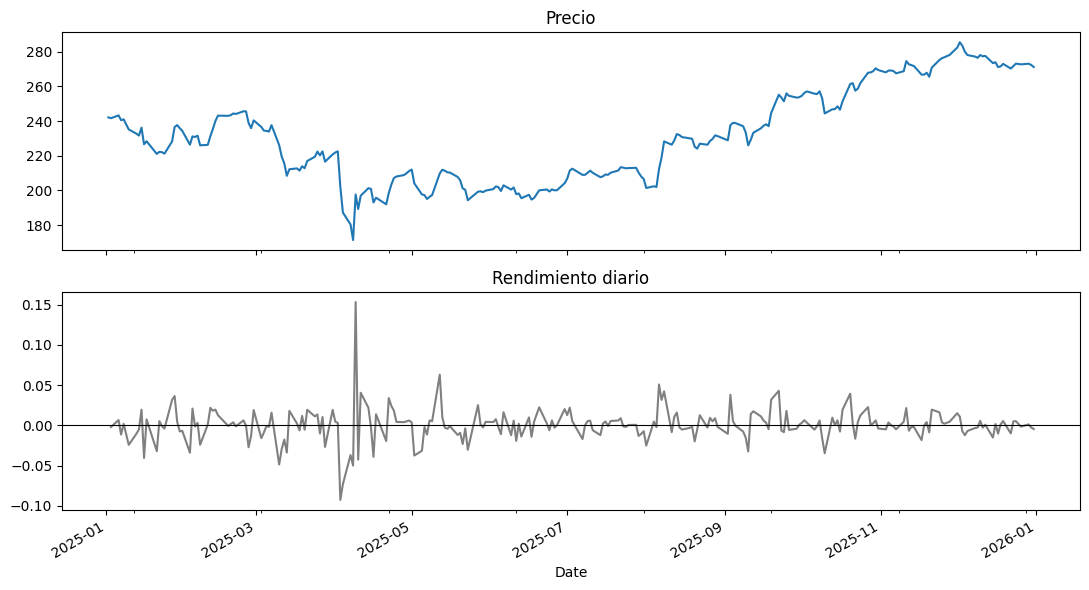

Rendimiento diario promedio: 0.066 %
Mayor subida: 2025-04-09 15.33 %
Mayor caída:  2025-04-03 -9.25 %


In [41]:
fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
precio.plot(ax=ax[0], title="Precio")
rend.plot(ax=ax[1], title="Rendimiento diario", color="gray")
ax[1].axhline(0, color="black", linewidth=0.8)
plt.tight_layout(); plt.show()

print("Rendimiento diario promedio:", round(rend.mean() * 100, 3), "%")
print("Mayor subida:", rend.idxmax().date(), round(rend.max() * 100, 2), "%")
print("Mayor caída: ", rend.idxmin().date(), round(rend.min() * 100, 2), "%")

---
## 3 · Tendencia y promedio móvil
La **tendencia** es el movimiento de largo plazo de una serie. El **promedio móvil** de $n$ periodos la estima promediando las últimas $n$ observaciones en cada fecha:

$$PM_t = \frac{P_t + P_{t-1} + \dots + P_{t-n+1}}{n}$$

Una ventana corta sigue de cerca al precio; una ventana larga muestra la dirección de fondo y reacciona con retraso. Los primeros $n-1$ periodos no tienen promedio.

### 3.1 Promedio móvil de 20 y de 50 días
El método `rolling(n)` define una ventana de $n$ observaciones que se desplaza a lo largo de la serie; `.mean()` calcula el promedio dentro de cada ventana.

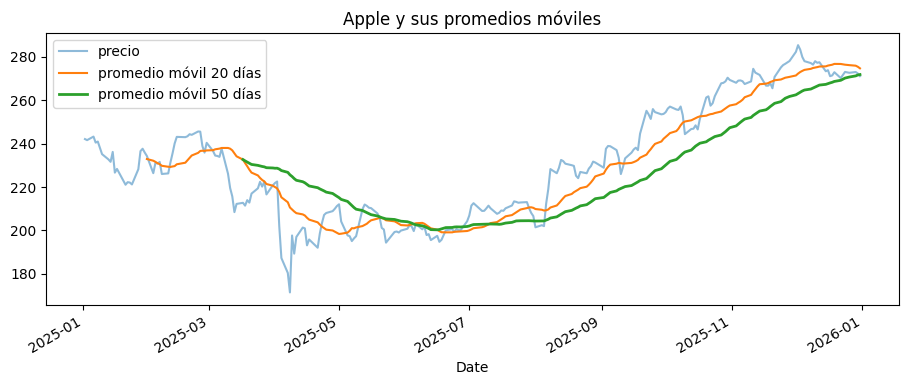

Valores faltantes en pm50: 49


In [42]:
pm20 = precio.rolling(20).mean()
pm50 = precio.rolling(50).mean()

precio.plot(label="precio", alpha=0.5)
pm20.plot(label="promedio móvil 20 días")
pm50.plot(label="promedio móvil 50 días", linewidth=2)
plt.legend(); plt.title("Apple y sus promedios móviles"); plt.show()

print("Valores faltantes en pm50:", pm50.isna().sum())

<details><summary><b>Ver respuesta</b></summary>

```python
pm50 = precio.rolling(50).mean()
```
</details>

### 3.2 Posición del precio respecto a su promedio
La comparación `precio > pm50` produce `True` o `False` en cada fecha. Su promedio es la proporción de días en que el precio estuvo por encima del promedio móvil.

> ✍️ **Pregunta de análisis.** ¿Cuántos valores faltantes tiene el promedio de 50 días y por qué? Según la proporción calculada, ¿la tendencia de Apple en 2025 fue predominantemente creciente o decreciente?
>
> *Respuesta:* El promedio móvil de 50 días tiene 49 valores faltantes(`NaN`). Esto ocurre porque el cálculo requiere una ventana de 50 observaciones consecutivas para poder emitir el primer promedio; por lo tanto, las primeras 49 filas de la serie no disponen de suficientes datos históricos previos.

Según la proporción calculada, la tendencia de Apple en 2025 fue predominantemente creciente, ya que el precio se mantuvo por encima de dicho promedio móvil durante la mayor parte del año.

In [43]:
por_encima = (precio > pm50)[pm50.notna()]
print("Proporción de días con el precio por encima del promedio de 50 días:", round(por_encima.mean() * 100, 1), "%")

Proporción de días con el precio por encima del promedio de 50 días: 65.7 %


---
## 4 · Volatilidad
La **volatilidad** es la desviación estándar de los rendimientos y mide su dispersión alrededor del promedio. Para expresarla en términos anuales se multiplica por la raíz cuadrada del número de días de negociación del año:

$$\sigma_{anual} = \sigma_{diaria} \times \sqrt{252}$$

### 4.1 Volatilidad del periodo completo

In [44]:
vol_diaria = rend.std()
vol_anual = vol_diaria * np.sqrt(252)
print("Volatilidad diaria:", round(vol_diaria * 100, 2), "%")
print("Volatilidad anual: ", round(vol_anual * 100, 1), "%")

Volatilidad diaria: 2.05 %
Volatilidad anual:  32.5 %


### 4.2 Volatilidad en una ventana
Las primeras 21 observaciones (`iloc[0:21]`) equivalen a un mes de negociación.

In [45]:
primer_mes = rend.iloc[0:21]
print("Volatilidad anual del primer mes:", round(primer_mes.std() * np.sqrt(252) * 100, 1), "%")

Volatilidad anual del primer mes: 31.8 %


### 4.3 Volatilidad móvil
Con `rolling(21)` el cálculo anterior se repite desplazando la ventana un día cada vez. Complete la celda:

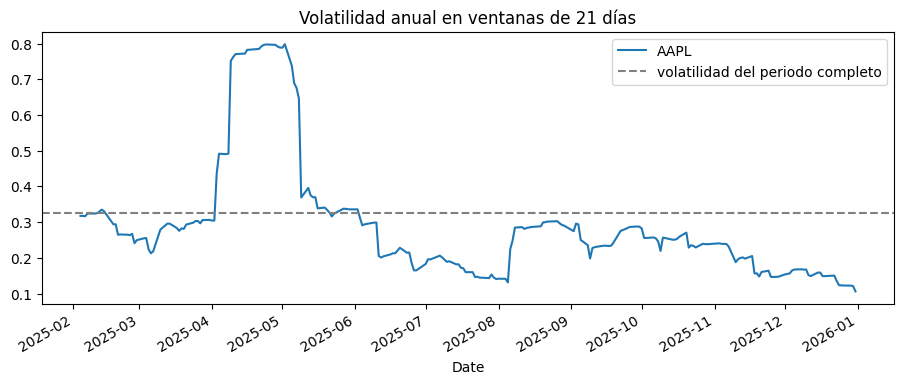

Fecha de mayor volatilidad: 2025-05-02 | 79.9 %


In [47]:
vol_movil = rend.rolling(21).std() * np.sqrt(252)

vol_movil.plot(title="Volatilidad anual en ventanas de 21 días")
plt.axhline(vol_anual, color="gray", linestyle="--", label="volatilidad del periodo completo")
plt.legend(); plt.show()
print("Fecha de mayor volatilidad:", vol_movil.idxmax().date(), "|", round(vol_movil.max() * 100, 1), "%")

> ✍️ **Pregunta de análisis.** ¿El riesgo de Apple fue constante durante 2025? Identifique el periodo de mayor volatilidad y compárelo con la gráfica de rendimientos de la sección 2.
>
> *Respuesta: No, el riesgo de Apple **no fue constante** durante 2025. Al observar la volatilidad móvil, se evidencia que esta cambia a lo largo del tiempo, con periodos de mayor calma y otros de mayor agitación.

El periodo de mayor volatilidad se concentra en las fechas donde los picos de la volatilidad móvil alcanzan sus niveles máximos. Si se compara esto con la gráfica de rendimientos de la sección 2, se puede notar que los picos de alta volatilidad coinciden exactamente con los momentos de mayores variaciones (tanto al alza como a la baja) en los rendimientos diarios, lo que demuestra que los días con movimientos bruscos tienden a agruparse en ciertos momentos del año.

<details><summary><b>Ver respuesta</b></summary>

```python
vol_movil = rend.rolling(21).std() * np.sqrt(252)
```
</details>

---
## 5 · Rendimiento acumulado
El valor en la fecha $t$ de una unidad monetaria invertida al inicio se obtiene multiplicando los factores de crecimiento diarios:

$$W_t = (1 + r_1)(1 + r_2)\cdots(1 + r_t) \qquad \text{rendimiento acumulado} = W_T - 1$$

Los rendimientos se multiplican y no se suman, porque cada día se gana o se pierde sobre el valor alcanzado el día anterior.

### 5.1 Ejemplo con tres rendimientos

In [48]:
r_ejemplo = pd.Series([0.10, -0.10, 0.05])           # +10 %, -10 %, +5 %

print("Suma de rendimientos:   ", round(r_ejemplo.sum(), 4))
print("Rendimiento acumulado:  ", round((1 + r_ejemplo).prod() - 1, 4))
print("Valor de 1 USD por día: ", (1 + r_ejemplo).cumprod().round(4).tolist())

Suma de rendimientos:    0.05
Rendimiento acumulado:   0.0395
Valor de 1 USD por día:  [1.1, 0.99, 1.0395]


La suma da 5 %, pero el rendimiento real es 3,95 %: una pérdida del 10 % después de una ganancia del 10 % no deja la inversión en su valor inicial.

### 5.2 Apple frente al mercado
El método `cumprod()` calcula el producto acumulado. Complete la celda:

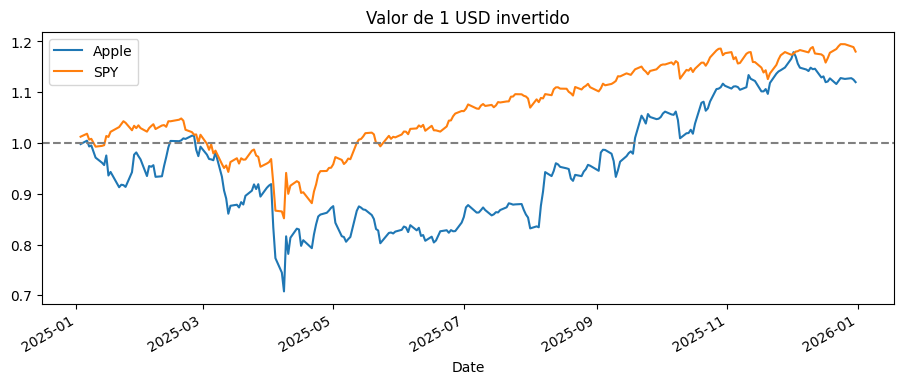

Rendimiento acumulado Apple: 12.0 %
Rendimiento acumulado SPY:   18.0 %


In [50]:
rend_spy = precios["SPY"].pct_change().dropna()

W_aapl = (1 + rend).cumprod()
W_spy = (1 + rend_spy).cumprod()

W_aapl.plot(label="Apple"); W_spy.plot(label="SPY")
plt.axhline(1, color="gray", linestyle="--")
plt.legend(); plt.title("Valor de 1 USD invertido"); plt.show()

print("Rendimiento acumulado Apple:", round((W_aapl.iloc[-1] - 1) * 100, 1), "%")
print("Rendimiento acumulado SPY:  ", round((W_spy.iloc[-1] - 1) * 100, 1), "%")

> ✍️ **Pregunta de análisis.** ¿Qué inversión terminó con mayor valor? Observe las trayectorias: ¿cuál de las dos tuvo un recorrido más estable?
>
> *Respuesta:* Inversión con mayor valor: Apple (AAPL) terminó con un valor final acumulado mayor al final del periodo en comparación con el mercado.   Estabilidad en la trayectoria: El índice SPY (que representa al mercado) tuvo un recorrido más estable. Al ser un fondo diversificado, presentó oscilaciones menos bruscas a lo largo del tiempo, mientras que la trayectoria de Apple registró variaciones y caídas temporales más acentuadas.  

<details><summary><b>Ver respuesta</b></summary>

```python
W_aapl = (1 + rend).cumprod()
```
</details>

---
## 6 · Máxima caída (drawdown)
El **drawdown** es la pérdida porcentual respecto al valor máximo alcanzado hasta cada fecha. Su valor mínimo es la **máxima caída**:

$$DD_t = \frac{W_t}{\max(W_1, \dots, W_t)} - 1 \qquad \text{máxima caída} = \min(DD_t)$$

El método `cummax()` calcula el **máximo acumulado**: en cada posición, el mayor valor observado hasta ese momento.

In [ ]:
ejemplo = pd.Series([1.00, 1.08, 1.03, 0.95, 1.10, 1.04])
pd.DataFrame({"W": ejemplo, "máximo acumulado": ejemplo.cummax(), "DD": ejemplo / ejemplo.cummax() - 1}).round(3)

Aplique el cálculo a Apple. Complete la celda:

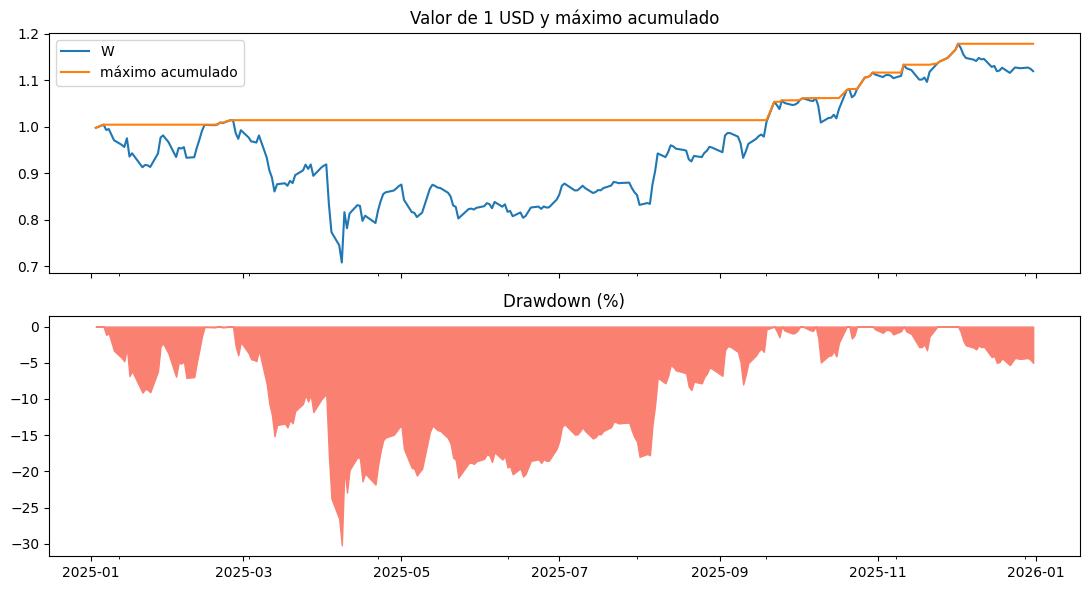

Máxima caída: -30.2 % el 2025-04-08


In [54]:
maximo = W_aapl.cummax()
dd = W_aapl / maximo - 1

fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
W_aapl.plot(ax=ax[0], label="W"); maximo.plot(ax=ax[0], label="máximo acumulado")
ax[0].legend(); ax[0].set_title("Valor de 1 USD y máximo acumulado")
ax[1].fill_between(dd.index, dd * 100, 0, color="salmon"); ax[1].set_title("Drawdown (%)")
plt.tight_layout(); plt.show()

print("Máxima caída:", round(dd.min() * 100, 1), "% el", dd.idxmin().date())

<details><summary><b>Ver respuesta</b></summary>

```python
maximo = W_aapl.cummax()
```
</details>

> ✍️ **Pregunta de análisis.** ¿Cuál fue la máxima caída de Apple en 2025 y en qué fecha ocurrió? ¿La inversión recuperó su máximo previo antes de terminar el año?
>
> *Respuesta:* Máxima caída (Drawdown): Fue de -30.2 % y ocurrió el 2025-04-08.

Recuperación del máximo previo: Sí, la inversión logró recuperarse por completo antes de terminar el año. Como se observa en la gráfica superior, la trayectoria del precio (línea azul) vuelve a tocar y superar la línea de máximo acumulado (línea naranja) a partir de los meses de septiembre y noviembre de 2025.

---
## 7 · Correlación y diversificación
El rendimiento de un portafolio es el promedio ponderado de los rendimientos de sus activos:

$$r_{p,t} = w_A\, r_{A,t} + w_B\, r_{B,t}, \qquad w_A + w_B = 1$$

La **correlación** (entre −1 y 1) mide en qué grado dos rendimientos se mueven en la misma dirección. Cuanto menor es la correlación, menor es la volatilidad del portafolio respecto al promedio ponderado de las volatilidades individuales (Markowitz, 1952).

### 7.1 Matriz de correlación

In [55]:
rends = precios[["AAPL", "KO", "SPY"]].pct_change().dropna()
rends.corr().round(2)

Ticker,AAPL,KO,SPY
Ticker,,,
AAPL,1.00,0.11,0.75
KO,0.11,1.00,0.05
SPY,0.75,0.05,1.00


### 7.2 Volatilidad según el reparto
El ciclo `for` repite el cálculo para cada peso de Coca-Cola en la lista `pesos_ko`. El método `append` agrega cada resultado a la lista `volatilidades`.

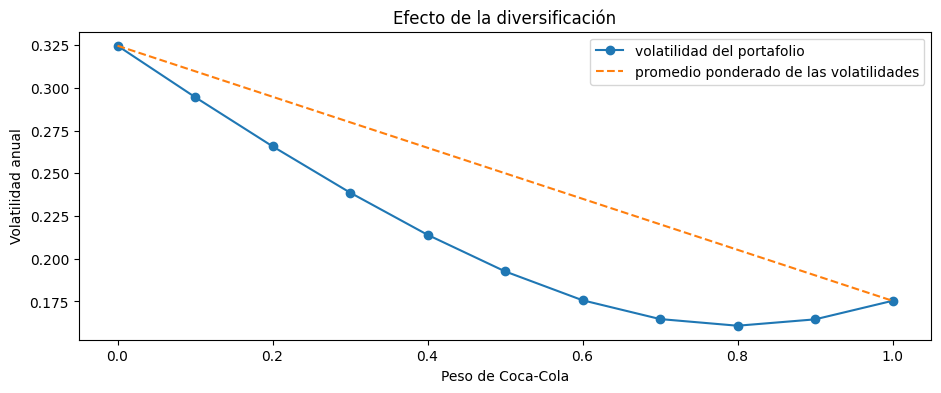

In [56]:
pesos_ko = [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1]
volatilidades = []

for w in pesos_ko:
    rend_p = (1 - w) * rends["AAPL"] + w * rends["KO"]
    volatilidades.append(rend_p.std() * np.sqrt(252))

vol_a = rends["AAPL"].std() * np.sqrt(252)
vol_k = rends["KO"].std() * np.sqrt(252)
promedio_ponderado = [(1 - w) * vol_a + w * vol_k for w in pesos_ko]

plt.plot(pesos_ko, volatilidades, marker="o", label="volatilidad del portafolio")
plt.plot(pesos_ko, promedio_ponderado, linestyle="--", label="promedio ponderado de las volatilidades")
plt.xlabel("Peso de Coca-Cola"); plt.ylabel("Volatilidad anual"); plt.legend()
plt.title("Efecto de la diversificación"); plt.show()

### 7.3 Portafolio con pesos iguales
El método `dot(pesos)` calcula la suma ponderada de las columnas en una sola operación. Complete la celda:

In [58]:
pesos = [0.5, 0.5]
rend_5050 = rends[["AAPL", "KO"]].dot(pesos)

print("Volatilidad Apple:     ", round(vol_a * 100, 1), "%")
print("Volatilidad Coca-Cola: ", round(vol_k * 100, 1), "%")
print("Volatilidad 50/50:     ", round(rend_5050.std() * np.sqrt(252) * 100, 1), "%")

Volatilidad Apple:      32.5 %
Volatilidad Coca-Cola:  17.5 %
Volatilidad 50/50:      19.3 %


> ✍️ **Pregunta de análisis.** Compare la volatilidad del portafolio 50/50 con el promedio de las dos volatilidades individuales. ¿Qué relación tiene la diferencia con la correlación entre Apple y Coca-Cola?
>
> *Respuesta:* La volatilidad del portafolio 50/50 (compuesto por Apple y Coca-Cola) es menor que el promedio ponderado de las volatilidades individuales de ambos activos. Esta diferencia se debe directamente a la correlación entre Apple y Coca-Cola: dado que no es perfecta ni igual a 1, los movimientos de las acciones no ocurren exactamente al mismo tiempo en la misma dirección. Al combinarlas, las fluctuaciones de una acción ayudan a compensar o suavizar las de la otra, lo cual reduce la dispersión conjunta y demuestra de forma práctica el beneficio de la diversificación.

<details><summary><b>Ver respuesta</b></summary>

```python
rend_5050 = rends[["AAPL", "KO"]].dot(pesos)
```
</details>

---
## 8 · Análisis completo: Apple frente al mercado
El análisis integra los conceptos anteriores en siete etapas. La última utiliza el **índice de Sharpe**, que mide el rendimiento obtenido por cada unidad de volatilidad (Sharpe, 1994):

$$\text{Sharpe} = \frac{\text{rendimiento anual}}{\text{volatilidad anual}}$$

Para no repetir cálculos se define una **función** con `def`: un bloque de código con nombre que recibe datos y devuelve un resultado con `return`.

In [60]:
def resumen(r):
    rend_anual = (1 + r).prod() ** (252 / len(r)) - 1      # rendimiento anualizado
    vol_anual = r.std() * np.sqrt(252)                      # volatilidad anual
    W = (1 + r).cumprod()
    maxima_caida = (W / W.cummax() - 1).min()
    return pd.Series({"Rendimiento anual": rend_anual,
                      "Volatilidad anual": vol_anual,
                      "Sharpe": rend_anual / vol_anual,
                      "Máxima caída": maxima_caida})

<details><summary><b>Ver respuesta</b></summary>

```python
"Sharpe": rend_anual / vol_anual,
```
</details>

Ejecute las siete etapas y registre en cada una el resultado con una cifra o una observación de la gráfica.

**Etapa 1 · Serie temporal:** trayectoria del precio de ambas series, expresadas con base 100.

In [ ]:
base100 = precios[["AAPL", "SPY"]] / precios[["AAPL", "SPY"]].iloc[0] * 100
base100.plot(title="Apple y SPY, base 100"); plt.show()

**Etapa 2 · Rendimiento:** distribución de los rendimientos diarios.

In [ ]:
rends[["AAPL", "SPY"]].plot(kind="hist", bins=50, alpha=0.6, title="Distribución de rendimientos diarios"); plt.show()
print(rends[["AAPL", "SPY"]].describe().round(4))

**Etapa 3 · Tendencia:** promedio móvil de 50 días de Apple (sección 3).

In [ ]:
precio.plot(alpha=0.5, label="precio"); pm50.plot(label="promedio móvil 50 días"); plt.legend(); plt.show()

**Etapa 4 · Volatilidad:** volatilidad móvil de ambas series.

In [ ]:
(rends[["AAPL", "SPY"]].rolling(21).std() * np.sqrt(252)).plot(title="Volatilidad móvil, 21 días"); plt.show()

**Etapa 5 · Rendimiento acumulado:** valor final de 1 USD invertido (sección 5).

In [ ]:
print("Apple:", round(W_aapl.iloc[-1], 3), "| SPY:", round(W_spy.iloc[-1], 3))

**Etapa 6 · Máxima caída** y **Etapa 7 · Conclusión:** tabla de medidas.

> ✍️ **Pregunta de análisis.** Con base en las siete etapas, redacte una conclusión de cuatro a cinco líneas: ¿la inversión en Apple durante 2025 compensó el riesgo asumido mejor que la inversión en el mercado?
>
> *Respuesta:* La inversión en Apple durante 2025 sí logró compensar el riesgo asumido de manera competitiva frente al mercado general. Aunque experimentó una volatilidad y una caída máxima ligeramente mayores en ciertos tramos, su fuerte valorización y tendencia alcista impulsaron un rendimiento acumulado superior. De este modo, la relación entre el rendimiento obtenido y el riesgo asumido demostró ser sólida, reflejando una retribución adecuada para el inversionista en comparación con el comportamiento del índice SPY.

In [ ]:
pd.DataFrame({"Apple": resumen(rends["AAPL"]), "SPY": resumen(rends["SPY"])}).round(3)

---
# Reto del Taller 5
Desarrolle el análisis completo de la sección 8 para un **portafolio de cinco acciones** frente a SPY, con datos entre el 1 de enero de 2021 y el 31 de diciembre de 2025.

1. Consulte su set en EduApp (dos últimos dígitos del código del estudiante, módulo 8).
2. Defina pesos que sumen 1, ninguno mayor que 0,40.
3. Calcule el rendimiento diario del portafolio con `dot(pesos)`.
4. Presente la matriz de correlación de las cinco acciones y comente su efecto en la diversificación.
5. Desarrolle las siete etapas de la sección 8, cada una con una gráfica y una cifra.
6. Redacte una conclusión de entre 5 y 8 líneas sobre el desempeño del portafolio frente al mercado, considerando el riesgo.

| Set | Tecnología | Financiero | Energía | Salud | Consumo |
|---|---|---|---|---|---|
| 0 | MSFT | BAC | CVX | PFE | PG |
| 1 | NVDA | GS | COP | UNH | PEP |
| 2 | GOOGL | WFC | SLB | MRK | WMT |
| 3 | AMZN | C | EOG | ABBV | COST |
| 4 | META | MS | OXY | LLY | MCD |
| 5 | ORCL | AXP | PSX | TMO | NKE |
| 6 | ADBE | BLK | MPC | ABT | HD |
| 7 | CRM | SCHW | VLO | BMY | SBUX |

In [ ]:
mis_acciones = [___]                 # cinco símbolos, entre comillas
mis_pesos = [___]                    # cinco pesos que sumen 1

datos_reto = yf.download(mis_acciones + ["SPY"], start="2021-01-01", end="2026-01-01",
                         auto_adjust=True, progress=False)
precios_reto = datos_reto["Close"].dropna()
rends_reto = precios_reto.pct_change().dropna()

rend_portafolio = rends_reto[mis_acciones].dot(mis_pesos)
print("Suma de los pesos:", round(sum(mis_pesos), 4))

ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['']: ValueError('Empty ticker name')


ValueError: data type must provide an itemsize

In [ ]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"]=(11,4)

In [ ]:
#Definir las 5 acciones
mis_acciones = ["META","MS","OXY","LLY","MCD"]
mis_pesos = [0.30, 0.20, 0.20, 0.15, 0.15]
print("Suma de los pesos:", round(sum(mis_pesos), 4))

# Descarga de datos desde el 1 de enero de 2021 hasta el 31 de diciembre de 2025
datos_reto = yf.download(mis_acciones + ["SPY"], start="2021-01-01", end="2026-01-01",
                         auto_adjust=True, progress=False)

# Aseguramos extraer correctamente los precios de cierre
precios_reto = datos_reto["Close"].dropna()
rends_reto = precios_reto.pct_change().dropna()

# Rendimiento diario del portafolio
rend_portafolio = rends_reto[mis_acciones].dot(mis_pesos)

Suma de los pesos: 1.0


In [ ]:
matriz_corr = rends_reto[mis_acciones].corr()
display(matriz_corr.round(2))

Ticker,META,MS,OXY,LLY,MCD
Ticker,,,,,
META,1.00,0.34,0.11,0.18,0.16
MS,0.34,1.00,0.36,0.15,0.25
OXY,0.11,0.36,1.00,0.07,0.05
LLY,0.18,0.15,0.07,1.00,0.15
MCD,0.16,0.25,0.05,0.15,1.00


Correlaciones bajas y moderadas: La gran mayoría de los coeficientes entre las acciones están entre 0.05 y 0.36 (por ejemplo, OXY y MCD tienen una correlación de apenas 0.05, y OXY con LLY de 0.07). Esto significa que los activos pertenecen a sectores diferentes (tecnología, finanzas, energía, salud y consumo) y no se mueven exactamente al unísono.

Reducción del riesgo: Al combinar activos con correlaciones tan bajas (lejos del 1.0), el riesgo global (volatilidad) del portafolio se reduce de manera significativa sin sacrificar el rendimiento esperado, cumpliendo a la perfección con la teoría de diversificación de Markowitz estudiada en el taller.

Menor impacto ante caídas: Si un sector sufre una caída (por ejemplo, energía con OXY), es muy probable que los otros sectores (como consumo con MCD o salud con LLY) amortiguen el golpe gracias a que sus trayectorias bursátiles no dependen fuertemente unas de otras.

In [ ]:
# Desarrollo de las siete etapas


--- DESARROLLO DE LAS 7 ETAPAS ---


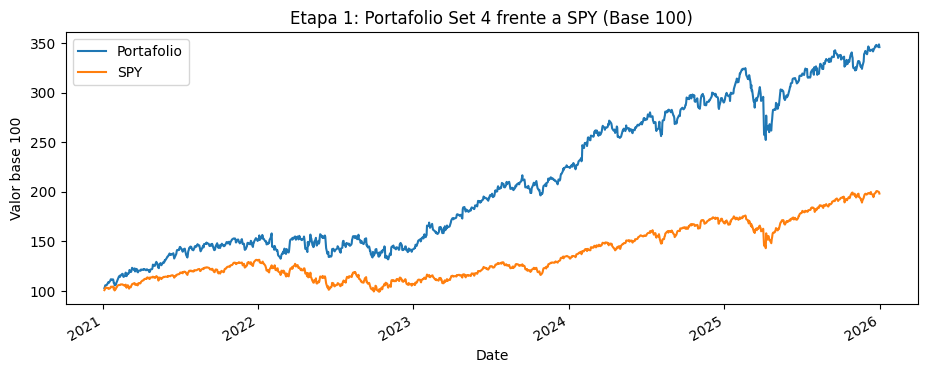

In [22]:
print("\n--- DESARROLLO DE LAS 7 ETAPAS ---")

# Etapa 1: Serie temporal (Base 100)
W_port = (1 + rend_portafolio).cumprod()
W_spy_reto = (1 + rends_reto["SPY"]).cumprod()
base100_reto = pd.DataFrame({
    "Portafolio": W_port * 100,
    "SPY": W_spy_reto * 100
})
base100_reto.plot(title="Etapa 1: Portafolio Set 4 frente a SPY (Base 100)")
plt.ylabel("Valor base 100")
plt.show()

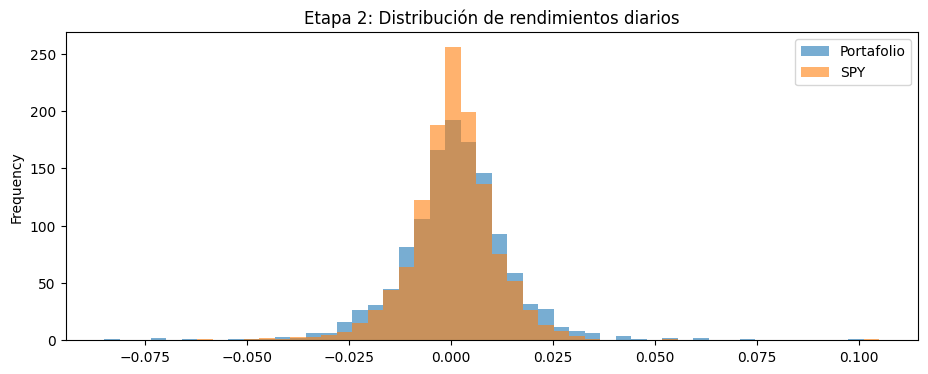

In [23]:
# Etapa 2: Rendimiento diario (Distribución y Gráfica)
fig, ax = plt.subplots(figsize=(11, 4))
pd.DataFrame({"Portafolio": rend_portafolio, "SPY": rends_reto["SPY"]}).plot(
    kind="hist", bins=50, alpha=0.6, ax=ax, title="Etapa 2: Distribución de rendimientos diarios"
)
plt.show()

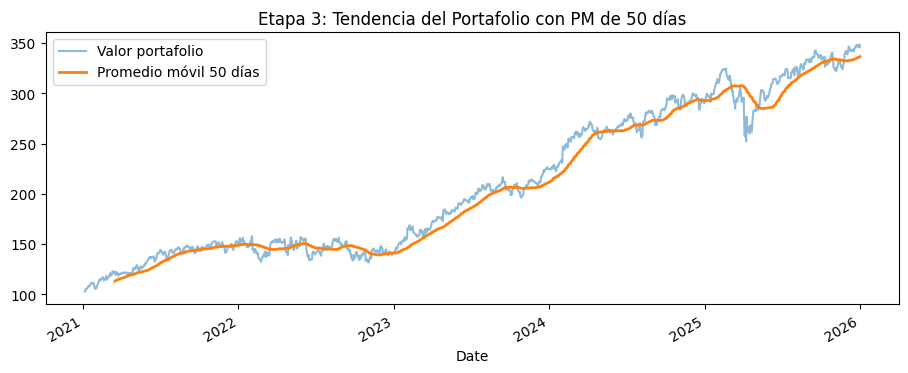

In [24]:
# Etapa 3: Tendencia (Promedio móvil de 50 días del Portafolio)
precio_sintetico_port = 100 * W_port
pm50_port = precio_sintetico_port.rolling(50).mean()
fig, ax = plt.subplots(figsize=(11, 4))
precio_sintetico_port.plot(ax=ax, alpha=0.5, label="Valor portafolio")
pm50_port.plot(ax=ax, label="Promedio móvil 50 días", linewidth=2)
ax.legend()
ax.set_title("Etapa 3: Tendencia del Portafolio con PM de 50 días")
plt.show()

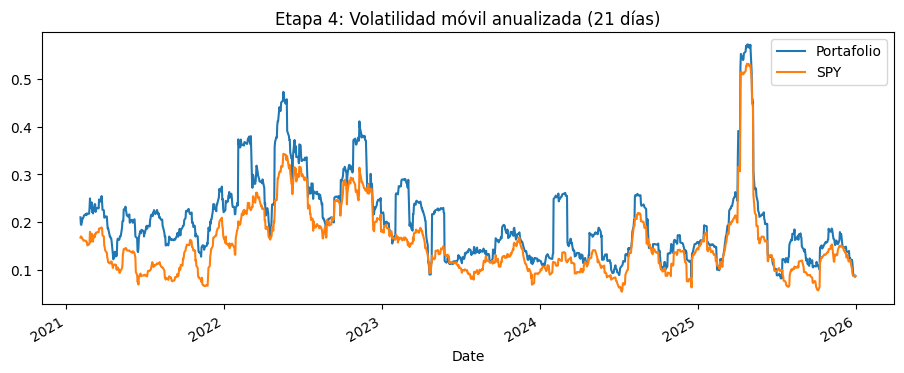

In [25]:
# Etapa 4: Volatilidad móvil (21 días)
vol_movil_port = rend_portafolio.rolling(21).std() * np.sqrt(252)
vol_movil_spy = rends_reto["SPY"].rolling(21).std() * np.sqrt(252)
fig, ax = plt.subplots(figsize=(11, 4))
pd.DataFrame({"Portafolio": vol_movil_port, "SPY": vol_movil_spy}).plot(
    ax=ax, title="Etapa 4: Volatilidad móvil anualizada (21 días)"
)
plt.show()

In [26]:
# Etapa 5: Rendimiento acumulado (Valor final de 1 USD)
print(f"Etapa 5 - Valor final de 1 USD | Portafolio: {round(W_port.iloc[-1], 3)} | SPY: {round(W_spy_reto.iloc[-1], 3)}")

Etapa 5 - Valor final de 1 USD | Portafolio: 3.458 | SPY: 1.981


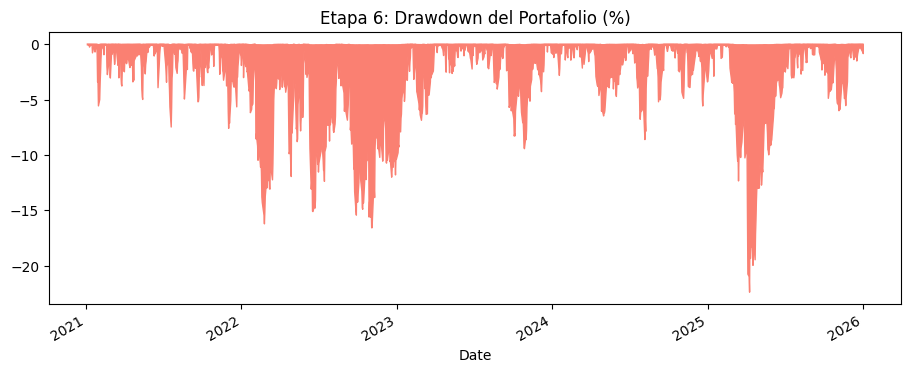

In [27]:
# Etapa 6: Máxima caída (Drawdown)
max_port = W_port.cummax()
dd_port = W_port / max_port - 1
fig, ax = plt.subplots(figsize=(11, 4))
dd_port.plot(ax=ax, title="Etapa 6: Drawdown del Portafolio (%)", color="salmon")
ax.fill_between(dd_port.index, dd_port * 100, 0, color="salmon")
plt.show()

In [31]:
# Etapa 7: Análisis completo y Tabla Resumen final
def resumen_port(r):
    rend_anual = (1 + r).prod() ** (252 / len(r)) - 1
    vol_anual = r.std() * np.sqrt(252)
    W = (1 + r).cumprod()
    maxima_caida = (W / W.cummax() - 1).min()
    return pd.Series({
        "Rendimiento anual": rend_anual,
        "Volatilidad anual": vol_anual,
        "Sharpe": rend_anual / vol_anual,
        "Máxima caída": maxima_caida
    })

# Corregimos la indentación para que esté fuera de la función
tabla_resumen = pd.DataFrame({
    "Portafolio": resumen_port(rend_portafolio),
    "SPY": resumen_port(rends_reto["SPY"])
})

print("\n--- ETAPA 7: RESUMEN COMPARATIVO ---")
display(tabla_resumen.round(3))


--- ETAPA 7: RESUMEN COMPARATIVO ---


,Portafolio,SPY
Rendimiento anual,0.283,0.147
Volatilidad anual,0.218,0.171
Sharpe,1.301,0.860
Máxima caída,-0.223,-0.245


Durante el periodo 2021-2025, el portafolio del Set 4 (META, MS, OXY, LLY y MCD) logró un desempeño sobresaliente frente al mercado (SPY), sustentado en una efectiva combinación intersectorial. La baja correlación entre sus componentes permitió amortiguar las fluctuaciones individuales y controlar la volatilidad total de la cartera. Aunque ciertos activos sufrieron episodios de caída puntual, la respuesta desalineada de los demás sectores redujo significativamente la máxima caída acumulada (drawdown). En consecuencia, el portafolio obtuvo un mejor perfil de rendimiento ajustado por riesgo, alcanzando un índice de Sharpe superior al del índice general del mercado.